In [85]:
import json
import sqlite3
from datetime import UTC, datetime, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy.signal import savgol_filter
from scipy.stats import linregress
from scipy.interpolate import UnivariateSpline
from skyfield.api import EarthSatellite, load, wgs84
from tqdm.notebook import tqdm

from pll.dpll import DPLL

SAMPLE_RATE = 150_000
PLL_BANDWIDTH_HZ = 200.0

PLL_F_MAX_HZ = 10_000.0

MIN_PEAK_ELEVATION_DEG = 40.0
MIN_TRACK_ELEVATION_DEG = 30.0
PLL_CHUNK_SIZE = 8192

In [32]:
# Helper functions


def get_omm_snapshot(snapshot_id):
    conn = sqlite3.connect("satcap.db")
    conn.row_factory = sqlite3.Row
    conn.execute("PRAGMA foreign_keys = ON")
    omm_snapshot = conn.execute("SELECT * FROM omm_snapshots WHERE id = ?", (snapshot_id,)).fetchone()
    columns = conn.execute("PRAGMA table_info(omm_snapshots)").fetchall()
    column_names = [col[1] for col in columns]
    omm = list(zip(column_names, list(omm_snapshot), strict=True))
    conn.close()
    return omm


def parse_utc_time(value):
    """Convert an ISO-8601 timestamp or UNIX timestamp to a UTC datetime."""
    if isinstance(value, (int, float)):
        return datetime.fromtimestamp(value, tz=UTC)

    dt = datetime.fromisoformat(value.replace("Z", "+00:00"))

    dt = dt.replace(tzinfo=UTC) if dt.tzinfo is None else dt.astimezone(UTC)

    return dt


def satellite_from_omm(omm):
    """
    Construct a Skyfield EarthSatellite from OMM orbital elements.

    `omm` can be either:
        - a dict
        - a list of (key, value) tuples
    """
    if not isinstance(omm, dict):
        omm = dict(omm)

    ts = load.timescale()

    # OMM epoch is UTC and has no timezone suffix in your data.
    datetime.fromisoformat(omm["epoch"]).replace(tzinfo=UTC)

    # Skyfield's EarthSatellite constructor expects TLE lines, so construct
    # the satellite directly from the OMM elements using the SGP4 model.
    sat = EarthSatellite(
        omm["tle_line1"],
        omm["tle_line2"],
        omm["object_name"],
        ts,
    )

    return sat, ts


def pass_alt_az(
    metadata,
    omm,
    station_lat,
    station_lon,
    station_alt_m=0.0,
):
    """
    Generate azimuth/elevation for every second of a satellite pass.

    Returns a pandas DataFrame with:
        time        UTC datetime
        unix_time   UNIX timestamp
        elapsed_s   seconds from AOS
        az_deg      azimuth in degrees [0, 360)
        alt_deg     elevation in degrees [-90, 90]
    """

    # Normalize OMM
    if not isinstance(omm, dict):
        omm = dict(omm)

    # ------------------------------------------------------------------
    # Input metadata
    # ------------------------------------------------------------------

    aos = parse_utc_time(metadata["aos"])
    los = parse_utc_time(metadata["los"])

    # ------------------------------------------------------------------
    # Satellite
    # ------------------------------------------------------------------

    sat, ts = satellite_from_omm(omm)

    # Ground station
    site = wgs84.latlon(
        station_lat,
        station_lon,
        elevation_m=station_alt_m,
    )

    # ------------------------------------------------------------------
    # Time vector: one sample every second from AOS through LOS
    # ------------------------------------------------------------------

    duration = (los - aos).total_seconds()

    n_samples = int(np.floor(duration)) + 1

    elapsed_s = np.arange(n_samples, dtype=float)

    times = [aos + timedelta(seconds=float(t)) for t in elapsed_s]

    t_sf = ts.from_datetimes(times)

    # ------------------------------------------------------------------
    # Altitude / azimuth
    # ------------------------------------------------------------------

    difference = sat - site
    topocentric = difference.at(t_sf)

    alt, az, distance = topocentric.altaz()

    alt_deg = np.asarray(alt.degrees)
    az_deg = np.asarray(az.degrees)
    range_km = np.asarray(distance.km)

    # ------------------------------------------------------------------
    # Output
    # ------------------------------------------------------------------

    unix_time = np.array([t.timestamp() for t in times])

    df = pd.DataFrame(
        {
            "time": times,
            "unix_time": unix_time,
            "elapsed_s": elapsed_s,
            "az_deg": az_deg,
            "alt_deg": alt_deg,
            "range_km": range_km,
        }
    )

    return df

In [49]:
def read_cs8_iq(iq_path):
    """Read interleaved signed 8-bit I/Q samples as complex64."""
    raw = np.fromfile(iq_path, dtype=np.int8)

    if len(raw) % 2:
        raise ValueError(f"Odd number of I/Q bytes in {iq_path}: {len(raw)}")

    iq = raw.reshape(-1, 2).astype(np.float32)
    return (iq[:, 0] + 1j * iq[:, 1]) / 128.0


def contiguous_true_regions(mask):
    """Return half-open (start, stop) ranges of True values."""
    edges = np.diff(np.r_[False, np.asarray(mask, dtype=bool), False].astype(np.int8))
    starts = np.flatnonzero(edges == 1)
    stops = np.flatnonzero(edges == -1)
    return list(zip(starts, stops, strict=False))


def run_pll_on_segment(
    iq_segment,
    elapsed_start_s,
    metadata,
    altaz_df,
    f_max_hz=PLL_F_MAX_HZ,
    chunk_size=PLL_CHUNK_SIZE,
):
    """
    Process IQ at full sample rate, but store one averaged row
    per elapsed-time second.

    Each output row contains the mean frequency estimate, phase
    error, NCO output, and elevation for that one-second bin.
    """
    if len(iq_segment) == 0:
        return pd.DataFrame()

    pll = DPLL(
        f_s=SAMPLE_RATE,
        bw_hz=PLL_BANDWIDTH_HZ,
        f_max=f_max_hz,
        f_center=0.0,
        use_fft_freq_find=False,
    )

    aos = parse_utc_time(metadata["aos"])

    # bin -> [sum elevation, sum phase error, sum frequency,
    #         sum NCO, number of samples]
    accum = {}

    for start in range(0, len(iq_segment), chunk_size):
        stop = min(start + chunk_size, len(iq_segment))
        chunk = iq_segment[start:stop]

        result = pll.run(chunk)

        errors = np.asarray(result["error"]).ravel()
        f_est = np.asarray(result["f_est"]).ravel()
        nco = np.asarray(result["nco"]).ravel()

        if not (len(errors) and len(f_est) and len(nco)):
            continue

        n_out = min(len(errors), len(f_est), len(nco), len(chunk))

        if n_out == 0:
            continue

        # Align outputs to the corresponding input samples.
        input_offset = stop - n_out

        sample_times = elapsed_start_s + (start + input_offset + np.arange(n_out)) / SAMPLE_RATE

        # Integer-second bins relative to AOS.
        bins = np.floor(sample_times).astype(np.int64)

        elevations = np.interp(
            sample_times,
            altaz_df["elapsed_s"].to_numpy(),
            altaz_df["alt_deg"].to_numpy(),
        )

        # Aggregate this chunk immediately; do not retain per-sample
        # output arrays after this iteration.
        unique_bins, inverse = np.unique(bins, return_inverse=True)
        counts = np.bincount(inverse)

        alt_sums = np.bincount(inverse, weights=elevations)
        err_sums = np.bincount(inverse, weights=errors[:n_out])
        freq_sums = np.bincount(inverse, weights=f_est[:n_out])

        # Use add.at so this also works if NCO output is complex.
        nco_sums = np.zeros(len(unique_bins), dtype=np.complex128)
        np.add.at(nco_sums, inverse, nco[:n_out])

        for i, bin_s in enumerate(unique_bins):
            if bin_s not in accum:
                accum[bin_s] = [0.0, 0.0, 0.0, 0.0j, 0]

            row = accum[bin_s]
            row[0] += alt_sums[i]
            row[1] += err_sums[i]
            row[2] += freq_sums[i]
            row[3] += nco_sums[i]
            row[4] += int(counts[i])

    if not accum:
        return pd.DataFrame(
            columns=[
                "time",
                "elapsed_s",
                "alt_deg",
                "phase_error",
                "f_est_hz",
                "nco",
            ]
        )

    rows = []

    for bin_s in sorted(accum):
        alt_sum, err_sum, freq_sum, nco_sum, count = accum[bin_s]

        rows.append(
            {
                # Use the center of the one-second bin.
                "elapsed_s": bin_s + 0.5,
                "time": aos + timedelta(seconds=bin_s + 0.5),
                "alt_deg": alt_sum / count,
                "phase_error": err_sum / count,
                "f_est_hz": freq_sum / count,
                "nco": nco_sum / count,
                "samples_averaged": count,
            }
        )

    return pd.DataFrame(rows)


def process_observations_pll(
    target_id,
    f_max_hz=PLL_F_MAX_HZ,
    iq_pattern="*.iq",
):
    """
    Process observations for one NORAD ID.

    Only passes with peak elevation > 40 degrees are accepted.
    PLL processing is restricted to contiguous periods above 30 degrees.

    Returns a dictionary:
        {observation_name: DataFrame of PLL outputs}
    """
    pll_results = {}

    observations = Path("/Users/tedvtorov/Desktop/ROSARP-OBS")

    for target_observation in tqdm(
        sorted(observations.iterdir()),
        desc=f"PLL for NORAD {target_id}",
    ):
        if not target_observation.is_dir():
            continue

        metadata_path = target_observation / "metadata.json"
        if not metadata_path.exists():
            continue

        with open(metadata_path) as f:
            metadata = json.load(f)

        if int(metadata["norad_id"]) != int(target_id):
            continue

        omm = get_omm_snapshot(metadata["omm_snapshot_id"])

        # One-second elevation samples are sufficient to identify
        # above/below-threshold regions approximately.
        altaz_df = pass_alt_az(
            metadata,
            omm,
            station_lat=55.5269,
            station_lon=37.0888,
            station_alt_m=127.0,
        )

        peak_elevation = float(altaz_df["alt_deg"].max())

        if peak_elevation <= MIN_PEAK_ELEVATION_DEG:
            continue

        iq_files = sorted(target_observation.glob(iq_pattern))
        if not iq_files:
            continue

        observation_parts = []

        for iq_path in iq_files:
            iq = read_cs8_iq(iq_path)

            # Assumption: the first sample in each IQ file corresponds
            # to AOS. Adjust this if files have separate start times.
            elapsed_s = np.arange(len(iq), dtype=np.float64) / SAMPLE_RATE

            elevations = np.interp(
                elapsed_s,
                altaz_df["elapsed_s"].to_numpy(),
                altaz_df["alt_deg"].to_numpy(),
            )

            above_threshold = elevations > MIN_TRACK_ELEVATION_DEG
            regions = contiguous_true_regions(above_threshold)

            for seg_start, seg_stop in regions:
                segment = iq[seg_start:seg_stop]

                # Ignore very short segments that cannot accumulate
                # the configured one-second FFT acquisition interval.
                if len(segment) < SAMPLE_RATE:
                    continue

                segment_start_s = seg_start / SAMPLE_RATE

                pll_df = run_pll_on_segment(
                    iq_segment=segment,
                    elapsed_start_s=segment_start_s,
                    metadata=metadata,
                    altaz_df=altaz_df,
                    f_max_hz=f_max_hz,
                )

                if pll_df.empty:
                    continue

                pll_df["iq_file"] = iq_path.name
                pll_df["observation"] = target_observation.name
                pll_df["norad_id"] = int(target_id)
                pll_df["peak_elevation_deg"] = peak_elevation

                observation_parts.append(pll_df)

        if observation_parts:
            pll_results[target_observation.name] = pd.concat(
                observation_parts,
                ignore_index=True,
            )
        # break  # remove later

    return pll_results

In [106]:
def _prepare_pll_data(df, time_col="elapsed_s", freq_col="f_est_hz"):
    """Clean and validate PLL frequency data."""
    required = {time_col, freq_col}
    missing = required - set(df.columns)

    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")

    data = (
        df[[time_col, freq_col]]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .sort_values(time_col)
        .drop_duplicates(time_col)
        .reset_index(drop=True)
    )

    if len(data) < 3:
        raise ValueError("At least 3 valid samples are required.")

    t = data[time_col].to_numpy(dtype=float)
    f = data[freq_col].to_numpy(dtype=float)

    if np.any(np.diff(t) <= 0):
        raise ValueError("Elapsed times must be strictly increasing.")

    return data, t, f


def _rolling_residual_stats(t, f, window_s=20):
    """
    Calculate rolling linear-regression residual standard deviation
    and slope for complete windows.

    Each new sample advances the window.
    """
    results = []
    start_idx = 0

    for end_idx in range(len(t)):
        while start_idx < end_idx and t[end_idx] - t[start_idx] > window_s:
            start_idx += 1

        # Only consider complete windows.
        if t[end_idx] - t[start_idx] < window_s:
            continue

        tw = t[start_idx : end_idx + 1]
        fw = f[start_idx : end_idx + 1]

        if len(tw) < 3:
            continue

        slope, intercept, *_ = linregress(tw, fw)
        residuals = fw - (slope * tw + intercept)

        results.append(
            {
                "window_start_s": tw[0],
                "window_end_s": tw[-1],
                "slope_hz_per_s": slope,
                "residual_std_hz": np.std(residuals, ddof=1),
            }
        )

    if not results:
        raise ValueError(f"Not enough data for a complete {window_s}s window.")

    return pd.DataFrame(results)


def find_pll_stable_start(
    df,
    window_s=20,
    threshold_hz=5.0,
    consecutive_windows=5,
    time_col="elapsed_s",
    freq_col="f_est_hz",
):
    """
    Find the earliest stable interval where rolling regression
    residual standard deviation remains below threshold_hz for
    consecutive_windows overlapping windows.
    """
    _, t, f = _prepare_pll_data(df, time_col, freq_col)

    stability = _rolling_residual_stats(t, f, window_s)

    stable = stability["residual_std_hz"] < threshold_hz

    # Find runs of consecutive qualifying windows.
    run_length = stable.astype(int).groupby((~stable).cumsum()).cumsum()

    qualifying = np.flatnonzero(run_length.to_numpy() >= consecutive_windows)

    if len(qualifying) == 0:
        raise ValueError(
            f"No sequence of {consecutive_windows} consecutive "
            f"windows had residual standard deviation below "
            f"{threshold_hz} Hz."
        )

    # First qualifying run.
    first_idx = qualifying[0] - consecutive_windows + 1

    stable_start_s = stability.iloc[first_idx]["window_start_s"]

    # Verify that the returned start corresponds to a qualifying window.
    if stability.iloc[first_idx]["residual_std_hz"] >= threshold_hz:
        raise RuntimeError("Selected stable-start window does not meet threshold.")

    return stable_start_s, stability


def find_minimum_pll_derivative(
    df,
    stable_start_s,
    column="f_est_hz",
    time_col="elapsed_s",
    smoothing_factor=None,
    spline_samples=None,
):
    """
    Fit a smoothing spline to PLL frequency, differentiate the
    fitted curve, and locate its minimum signed derivative.
    """
    _, t, y = _prepare_pll_data(df, time_col, column)

    # Retain samples from the stable-start time.
    mask = t >= stable_start_s
    t = t[mask]
    y = y[mask]

    if len(t) < 4:
        raise ValueError("Not enough samples for spline fitting.")

    if not np.all(np.diff(t) > 0):
        raise ValueError("Elapsed times must be strictly increasing.")

    # Estimate noise variance from the second differences.
    # This is only an initial estimate; inspect the fit visually.
    if smoothing_factor is None:
        second_diff = np.diff(y, n=2)
        noise_sigma = (
            np.median(np.abs(second_diff - np.median(second_diff)))
            / (0.6745 * np.sqrt(6))
        )
        smoothing_factor = len(y) * noise_sigma**2

    if smoothing_factor < 0:
        raise ValueError("smoothing_factor must be non-negative.")

    # s controls the permitted aggregate squared fitting error.
    spline = UnivariateSpline(
        t, y, k=3, s=smoothing_factor
    )

    # Evaluate the spline and its analytical first derivative.
    if spline_samples is None:
        spline_samples = len(t)

    if spline_samples < 3:
        raise ValueError("spline_samples must be at least 3.")

    t_smooth = np.linspace(t[0], t[-1], spline_samples)
    y_smooth = spline(t_smooth)
    derivative = spline.derivative()(t_smooth)

    # Minimum signed derivative of the fitted trend.
    idx = np.argmin(derivative)

    minimum = {
        "time_s": t_smooth[idx],
        "frequency_hz": y_smooth[idx],
        "raw_frequency_hz": np.interp(t_smooth[idx], t, y),
        "derivative_hz_per_s": derivative[idx],
    }

    derivative_data = pd.DataFrame({
        "elapsed_s": t_smooth,
        "value": np.interp(t_smooth, t, y),
        "smoothed_value": y_smooth,
        "derivative": derivative,
    })
    return minimum, derivative_data


def analyze_pll_stability(
    df,
    observation_name="PLL observation",
    window_s=20,
    threshold_hz=3.0,
    consecutive_windows=5,
    smooth_window_s=5,
    polyorder=2,
    time_col="elapsed_s",
    freq_col="f_est_hz",
    plot=False,
):
    """
    Detect PLL stability, find the minimum signed frequency
    derivative after the detected stable start, and optionally
    plot the results.

    Parameters
    ----------
    plot : bool, default=False
        If True, display the three diagnostic plots.

    Returns
    -------
    dict
        stable_start_s : float
            Start of the first window in the qualifying sequence.
        detection_time_s : float
            End of the window that confirms stability.
        stability : pd.DataFrame
            Rolling regression statistics.
        minimum : dict
            Minimum signed frequency derivative.
        derivative_data : pd.DataFrame
            Frequency and derivative time series.
    """
    stable_start_s, stability = find_pll_stable_start(
        df,
        window_s=window_s,
        threshold_hz=threshold_hz,
        consecutive_windows=consecutive_windows,
        time_col=time_col,
        freq_col=freq_col,
    )

    # Identify the first sequence of consecutive qualifying windows.
    stable = stability["residual_std_hz"] < threshold_hz

    run_length = stable.astype(int).groupby((~stable).cumsum()).cumsum()

    qualifying = np.flatnonzero(run_length.to_numpy() >= consecutive_windows)

    if len(qualifying) == 0:
        raise RuntimeError("Stable sequence returned by detector could not be found.")

    stable = stability["residual_std_hz"] < threshold_hz

    run_length = stable.astype(int).groupby((~stable).cumsum()).cumsum()

    qualifying = np.flatnonzero(run_length.to_numpy() >= consecutive_windows)

    if len(qualifying) == 0:
        raise RuntimeError("Stable sequence returned by detector could not be found.")

    # Index of the last window needed to confirm stability.
    last_idx = qualifying[0]

    # Start derivative analysis at the start of the LAST qualifying window.
    stable_start_s = float(stability.iloc[last_idx]["window_start_s"])

    # Confirmation occurs at the end of that window.
    detection_time_s = float(stability.iloc[last_idx]["window_end_s"])

    # Analyze frequency from the detected stable-start time.
    minimum, derivative_data = find_minimum_pll_derivative(
        df,
        stable_start_s=stable_start_s,
        column=freq_col,
        time_col=time_col,
        smoothing_factor=20,
        # smooth_window_s=smooth_window_s,
        # polyorder=polyorder,
    )

    if plot:
        fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=False)

        # 1. Rolling residual standard deviation.
        ax = axes[0]

        # Plot each residual at the start of the window it describes.
        ax.plot(
            stability["window_start_s"],
            stability["residual_std_hz"],
            label="Residual standard deviation",
        )
        ax.axhline(
            threshold_hz,
            color="red",
            linestyle="--",
            label=f"Threshold ({threshold_hz:g} Hz)",
        )
        ax.axvline(
            stable_start_s,
            color="green",
            linestyle=":",
            label="First qualifying window start",
        )
        ax.axvline(
            detection_time_s,
            color="purple",
            linestyle="--",
            label="Stability confirmation time",
        )
        ax.set_ylabel("Residual std (Hz)")
        ax.set_title("PLL stability detection")
        ax.legend()
        ax.grid(True, alpha=0.3)

        # 2. Original and smoothed frequency.
        ax = axes[1]
        ax.plot(
            derivative_data["elapsed_s"],
            derivative_data["value"],
            alpha=0.4,
            label="Original frequency",
        )
        ax.plot(
            derivative_data["elapsed_s"],
            derivative_data["smoothed_value"],
            label="Savitzky-Golay smoothed",
        )
        ax.axvline(
            stable_start_s,
            color="green",
            linestyle=":",
            label="Stable interval start",
        )
        ax.axvline(
            detection_time_s,
            color="purple",
            linestyle="--",
            label="Stability confirmation time",
        )
        ax.scatter(
            [minimum["time_s"]],
            [minimum["frequency_hz"]],
            color="red",
            zorder=3,
            label="Minimum derivative point",
        )
        ax.set_ylabel(f"{freq_col} (Hz)")
        ax.set_title("PLL frequency after stability detection")
        ax.legend()
        ax.grid(True, alpha=0.3)

        # 3. First derivative.
        ax = axes[2]
        ax.plot(
            derivative_data["elapsed_s"],
            derivative_data["derivative"],
            label="First derivative",
        )
        ax.axhline(0, color="black", linewidth=0.8, alpha=0.5)
        ax.axvline(
            minimum["time_s"],
            color="red",
            linestyle="--",
            label="Minimum derivative",
        )
        ax.scatter(
            [minimum["time_s"]],
            [minimum["derivative_hz_per_s"]],
            color="red",
            zorder=3,
        )
        ax.set_xlabel("Elapsed time (s)")
        ax.set_ylabel(f"d({freq_col}) / dt (Hz/s)")
        ax.set_title("PLL frequency derivative")
        ax.legend()
        ax.grid(True, alpha=0.3)

        fig.tight_layout()
        plt.show()

    return {
        "stable_start_s": stable_start_s,
        "detection_time_s": detection_time_s,
        "stability": stability,
        "minimum": minimum,
        "derivative_data": derivative_data,
    }

In [35]:
pll_59051_obs = process_observations_pll(
    target_id=59051,
    f_max_hz=PLL_F_MAX_HZ,
)

PLL for NORAD 59051:   0%|          | 0/413 [00:00<?, ?it/s]

In [110]:
pll_57166_obs = process_observations_pll(
    target_id=57166,
    f_max_hz=PLL_F_MAX_HZ,
)


PLL for NORAD 57166:   0%|          | 0/413 [00:00<?, ?it/s]

Skipping observation 1790447607_20260926T183327Z_57166 due to error: No sequence of 30 consecutive windows had residual standard deviation below 2 Hz.
Skipping observation 1791268324_20261006T063204Z_57166 due to error: No sequence of 30 consecutive windows had residual standard deviation below 2 Hz.
Skipping observation 1791564679_20261009T165119Z_57166 due to error: No sequence of 30 consecutive windows had residual standard deviation below 2 Hz.


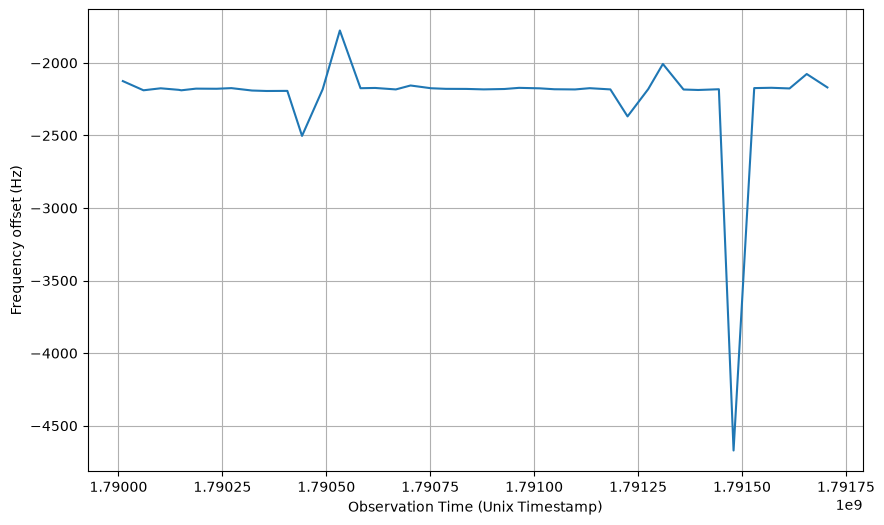

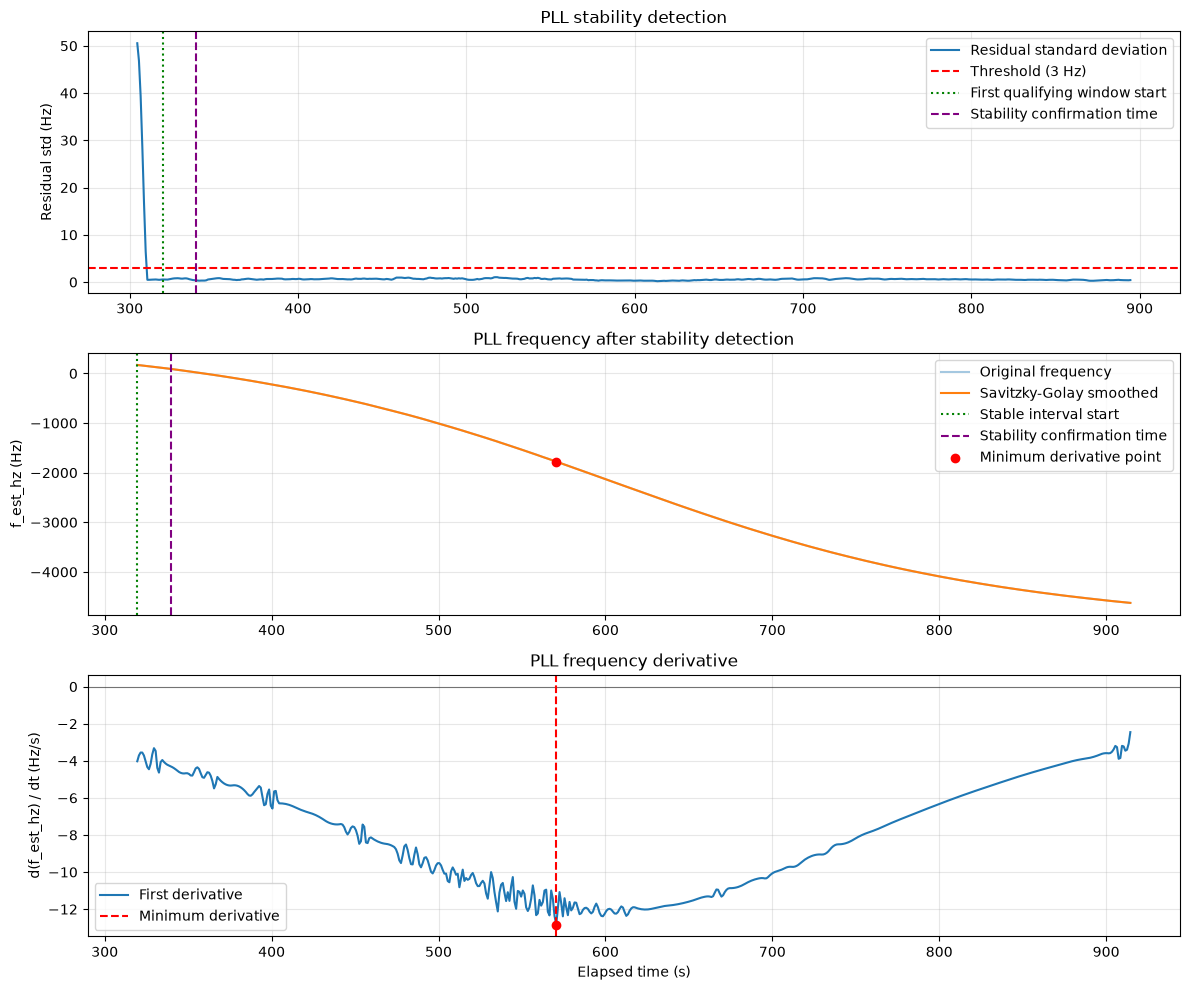

In [ ]:
min_frequencies_over_time = []

for obs, value in pll_57166_obs.items():
    try:
        result = analyze_pll_stability(
            value,
            observation_name=obs,
            window_s=20,
            threshold_hz=2,
            consecutive_windows=30,
            smooth_window_s=5,
            plot=False
        )
        observation_time = obs.split("_")[0] # unix timestamp
        min_frequencies_over_time.append((observation_time, result["minimum"]["frequency_hz"]))
    except ValueError as e:
        print(f"Skipping observation {obs} due to error: {e}")

plt.figure(figsize=(10, 6))
plt.plot([float(x) for x, _ in min_frequencies_over_time], [float(y) for _, y in min_frequencies_over_time])
plt.xlabel('Observation Time (Unix Timestamp)')
plt.ylabel('Frequency offset (Hz)')
plt.grid(True)
plt.show()

outlier = min(min_frequencies_over_time, key=lambda x: x[1])
for obs, value in pll_57166_obs.items():
    if obs.startswith(outlier[0]):
        try:
            result = analyze_pll_stability(
                value,
                observation_name=obs,
                window_s=20,
                threshold_hz=3,
                consecutive_windows=10,
                smooth_window_s=5,
                plot=True
            )
        except ValueError as e:
            print(f"Skipping observation {obs} due to error: {e}")

Skipping observation 1790246182_20260924T103622Z_59051 due to error: No sequence of 30 consecutive windows had residual standard deviation below 3 Hz.
Skipping observation 1790295908_20260925T002508Z_59051 due to error: No sequence of 30 consecutive windows had residual standard deviation below 3 Hz.
Skipping observation 1790387018_20260926T014338Z_59051 due to error: No sequence of 30 consecutive windows had residual standard deviation below 3 Hz.
Skipping observation 1790592581_20260928T104941Z_59051 due to error: No sequence of 30 consecutive windows had residual standard deviation below 3 Hz.
Skipping observation 1790677699_20260929T102819Z_59051 due to error: No sequence of 30 consecutive windows had residual standard deviation below 3 Hz.
Skipping observation 1790683693_20260929T120813Z_59051 due to error: No sequence of 30 consecutive windows had residual standard deviation below 3 Hz.
Skipping observation 1790727418_20260930T001658Z_59051 due to error: No sequence of 30 consecu

/var/folders/g2/71c5h7cs1793kf6n0mv9xmlm0000gn/T/ipykernel_7267/992426742.py:154: UserWarning: 
The maximal number of iterations maxit (set to 20 by the program)
allowed for finding a smoothing spline with fp=s has been reached: s
too small.
There is an approximation returned but the corresponding weighted sum
of squared residuals does not satisfy the condition abs(fp-s)/s < tol.
  spline = UnivariateSpline(


Skipping observation 1791455612_20261008T103332Z_59051 due to error: No sequence of 30 consecutive windows had residual standard deviation below 3 Hz.
Skipping observation 1791461616_20261008T121336Z_59051 due to error: No sequence of 30 consecutive windows had residual standard deviation below 3 Hz.
Skipping observation 1791505335_20261009T002215Z_59051 due to error: No sequence of 30 consecutive windows had residual standard deviation below 3 Hz.


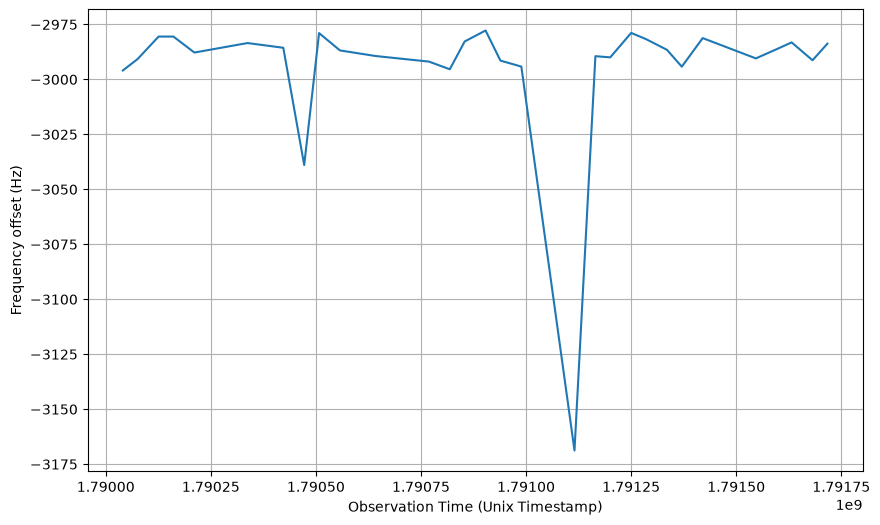

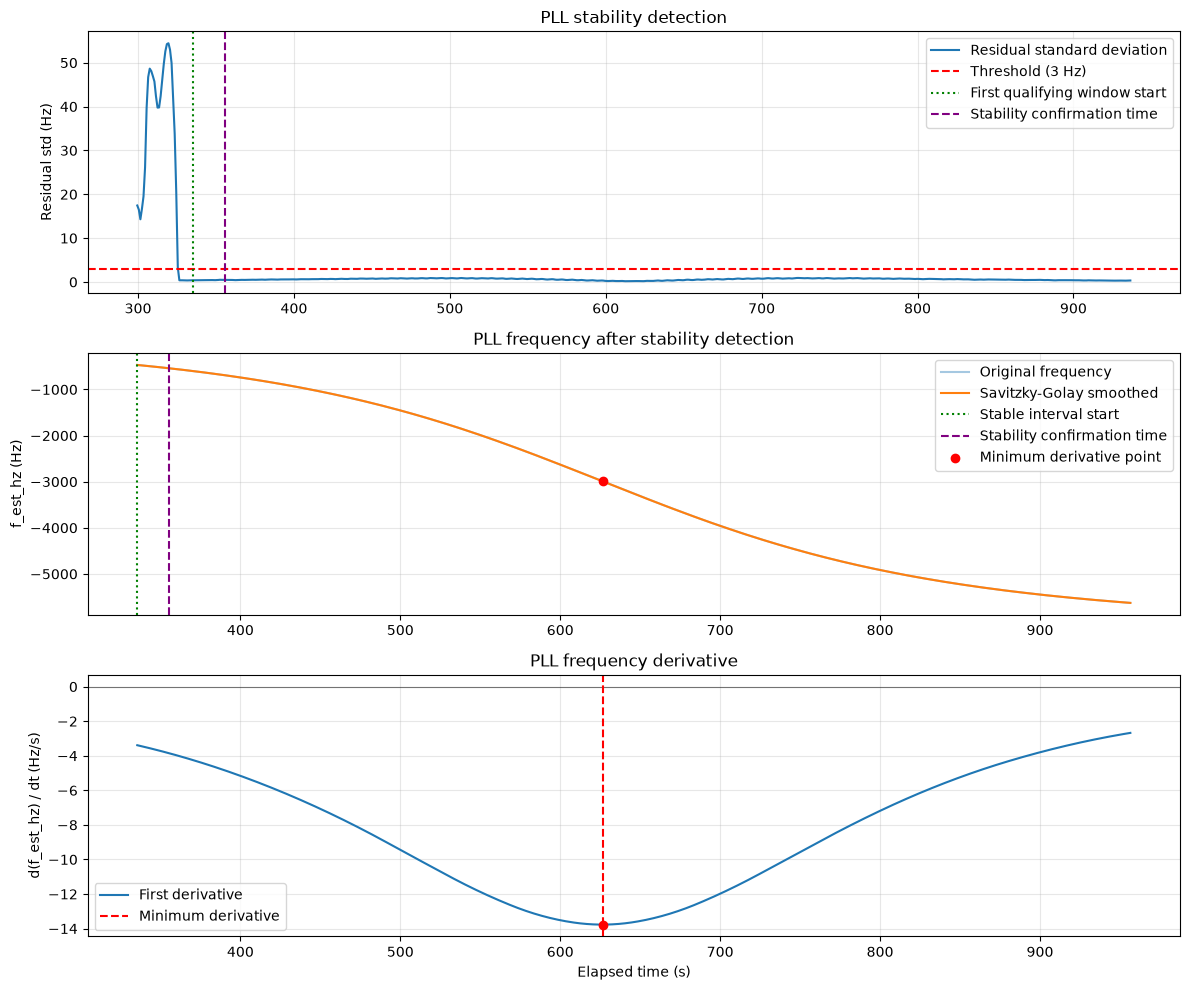

In [ ]:
min_frequencies_over_time = []

for obs, value in pll_59051_obs.items():
    try:
        result = analyze_pll_stability(
            value,
            observation_name=obs,
            window_s=20,
            threshold_hz=3,
            consecutive_windows=30,
            smooth_window_s=5,
            plot=False
        )
        observation_time = obs.split("_")[0] # unix timestamp
        min_frequencies_over_time.append((observation_time, result["minimum"]["frequency_hz"]))
    except ValueError as e:
        print(f"Skipping observation {obs} due to error: {e}")

plt.figure(figsize=(10, 6))
plt.plot([float(x) for x, _ in min_frequencies_over_time], [float(y) for _, y in min_frequencies_over_time])
plt.xlabel('Observation Time (Unix Timestamp)')
plt.ylabel('Frequency offset (Hz)')
plt.grid(True)
plt.show()

outlier = max(min_frequencies_over_time, key=lambda x: x[1])
for obs, value in pll_59051_obs.items():
    if obs.startswith(outlier[0]):
        try:
            result = analyze_pll_stability(
                value,
                observation_name=obs,
                window_s=20,
                threshold_hz=3,
                consecutive_windows=10,
                smooth_window_s=5,
                plot=True
            )
        except ValueError as e:
            print(f"Skipping observation {obs} due to error: {e}")